In [1]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
import glob
import random

In [10]:
# --- CONFIGURATION ---
# Path to the dataset folder created by the previous script
DATASET_DIR = "/home/usmanklodhi/TROGS-26/data/processed/greek_letters_obb" 
SPLIT = "val"  # 'train' or 'val'

In [11]:
def visualize_random_samples(num_samples=3):
    image_dir = os.path.join(DATASET_DIR, "images", SPLIT)
    label_dir = os.path.join(DATASET_DIR, "labels", SPLIT)
    
    # Get all images
    image_paths = glob.glob(os.path.join(image_dir, "*.jpg"))
    if not image_paths:
        print(f"No images found in {image_dir}")
        return

    # Pick random images
    samples = random.sample(image_paths, min(len(image_paths), num_samples))

    plt.figure(figsize=(15, 5 * num_samples))

    for i, img_path in enumerate(samples):
        # 1. Load Image
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w, _ = img.shape
        
        # 2. Load Corresponding Label
        basename = os.path.basename(img_path).replace(".jpg", ".txt")
        label_path = os.path.join(label_dir, basename)
        
        if os.path.exists(label_path):
            with open(label_path, 'r') as f:
                lines = f.readlines()
                
            for line in lines:
                parts = line.strip().split()
                class_id = int(parts[0])
                coords = [float(p) for p in parts[1:]]
                
                # 3. Denormalize Coordinates (0-1 -> Pixel Values)
                # YOLO format is: x1 y1 x2 y2 x3 y3 x4 y4 (normalized)
                points = []
                for j in range(0, len(coords), 2):
                    px = int(coords[j] * w)
                    py = int(coords[j+1] * h)
                    points.append([px, py])
                
                points = np.array(points, np.int32)
                points = points.reshape((-1, 1, 2))
                
                # 4. Draw the Polygon (OBB)
                # Draw box in Green, thickness 2
                cv2.polylines(img, [points], isClosed=True, color=(0, 255, 0), thickness=2)
                
                # Draw the starting point (to see orientation) in Red
                cv2.circle(img, tuple(points[0][0]), 5, (255, 0, 0), -1)

        # 5. Plot
        plt.subplot(num_samples, 1, i + 1)
        plt.imshow(img)
        plt.title(f"Sample: {os.path.basename(img_path)}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


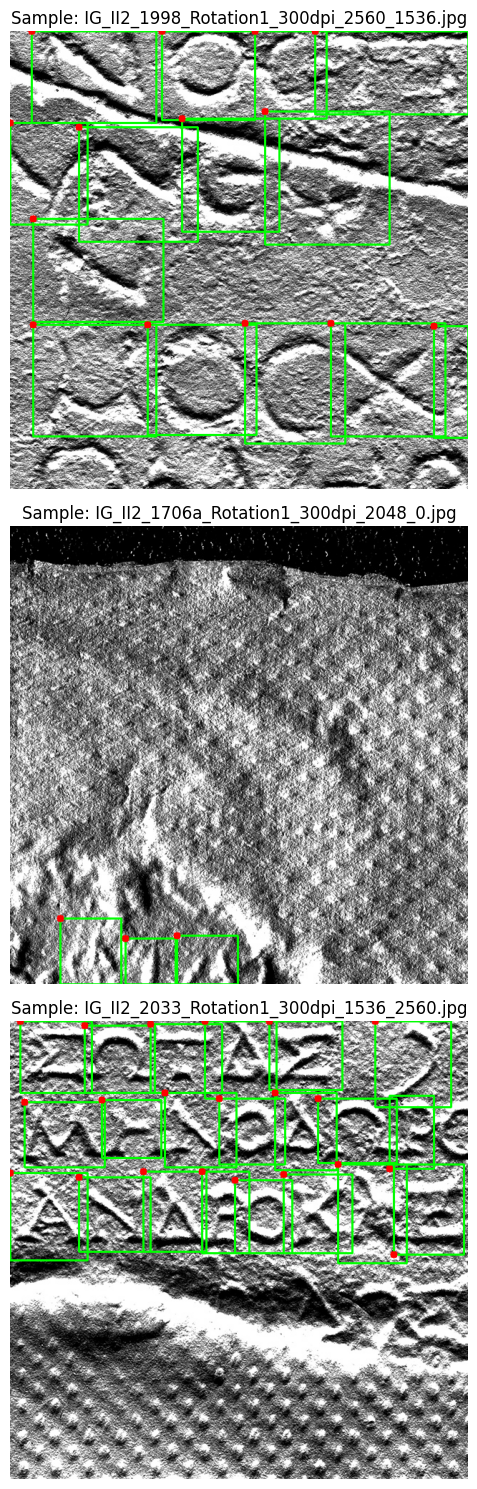

In [16]:
# Run the visualization
visualize_random_samples(3)